# Linear algebra 7: Symmetric matrices and positive definiteness

*Learning path: linear algebra, part 7 of 9.* [Index](README.md) · Previous: [Eigenvalues](06-eigenvalues.ipynb) · Next: [The singular value decomposition](08-svd.ipynb)

The stiffness of a structure, the covariance of data, the energy of a vibrating system, the Hessian of a function at a
minimum: all are **symmetric matrices**, equal to their own transpose. They are the best-behaved matrices there are.
Their eigenvalues are real, their eigenvectors are perpendicular, and when all eigenvalues are positive the matrix is
**positive definite**, which is the matrix version of "a positive number" and of "a bowl-shaped minimum".

**Who this is for.** You know eigenvalues and diagonalization ([lesson 6](06-eigenvalues.ipynb)) and orthonormal
vectors ([lesson 5](05-orthogonality.ipynb)). Section 5 connects to the second derivative test of
[multivariable lesson 3](../multivariable/03-optimization.ipynb), which helps but is not needed.

**What you will be able to do afterwards:**

1. diagonalize a symmetric matrix with an orthogonal matrix, $S = Q\Lambda Q^T$ (the spectral theorem);
2. untilt a quadratic form $x^TSx$ and find the axes of an ellipse;
3. test positive definiteness five ways: eigenvalues, pivots, determinants, energy, $A^TA$;
4. factor $S = LL^T$ (Cholesky) and use it as the fastest test.

Plan about an hour and a half.

## 1. The spectral theorem

Take $S = [5\ 2;\ 2\ 2]$, symmetric. Its eigenvalues are real and its eigenvectors perpendicular:

In [1]:
S = [5 2; 2 2];
[V, D] = eig(S)
dot(column(V, 1), column(V, 2))

V = [-1/2, 2;
    1, 1]
D = [1, 0;
 0, 6]
0

> `dot`: Dot product of two vectors, and cross product of two vectors of length 3.

Normalize the eigenvectors (Gram–Schmidt does nothing else here, since they are already perpendicular) and put them in
an orthogonal matrix $Q$. Then $Q^{-1} = Q^T$ and

$$S = Q\Lambda Q^T,$$

with $\Lambda$ the diagonal matrix of eigenvalues. This is the **spectral theorem**: *every real symmetric matrix can be
diagonalized by an orthogonal matrix*, with real eigenvalues. No complex numbers, no missing eigenvectors.

In [2]:
Q = gramschmidt(V)
Q*D*transpose(Q)

[ -sqrt(5)/5, 2*sqrt(5)/5;
 2*sqrt(5)/5,   sqrt(5)/5]

> Gram–Schmidt takes the columns one at a time, subtracts their projections on the directions found so far, and divides by the length: q₁ = a₁/|a₁|, then q₂ is a₂ − (q₁·a₂)q₁ normalized, and so on. 2 of the 2 columns were independent, so the columns of the result are an orthonormal basis of the column space (dimension 2).

[5, 2;
 2, 2]

Why perpendicular? If $Sx = \lambda x$ and $Sy = \mu y$ with $\lambda \ne \mu$, then
$\lambda\,x\cdot y = (Sx)\cdot y = x\cdot(Sy) = \mu\,x\cdot y$, using $S = S^T$ in the middle. So $x\cdot y = 0$.

Multiplying out $Q\Lambda Q^T$ column by column gives another way to read it: $S$ is a sum of projections onto its
eigenvector directions, weighted by the eigenvalues,

$$S = \lambda_1 q_1q_1^T + \lambda_2 q_2q_2^T + \cdots.$$

In [3]:
q1 = column(Q, 1);
q2 = column(Q, 2);
1*q1*transpose(q1) + 6*q2*transpose(q2)

[5, 2;
 2, 2]

**Try this.** Find the eigenvalues and perpendicular eigenvectors of $[0\ 1;\ 1\ 0]$ by hand. (It swaps the two
coordinates: which vectors does it keep, and which does it flip?)

## 2. Quadratic forms and tilted ellipses

A symmetric matrix defines a **quadratic form** $x^TSx$, a polynomial with only second-degree terms:

In [4]:
expand([x y]*S*[x; y])

5*x^2+4*x*y+2*y^2

> `expand`: Multiplies out products and powers.

The level curve $5x^2 + 4xy + 2y^2 = 1$ is a tilted ellipse. In the eigenvector coordinates
$x = Qu$ the cross term disappears: $x^TSx = u^T\Lambda u = 1\cdot u_1^2 + 6\,u_2^2$. So the ellipse has its axes along
the eigenvectors, with half-lengths $1/\sqrt{\lambda}$: length 1 along $q_1 \propto [-1\ 2]$ and $1/\sqrt6$ along
$q_2 \propto [2\ 1]$. This is how [foundations lesson 9](../foundations/09-geometry-and-conics.ipynb) untilted conics.

The plot shows the ellipse and its two axes, the eigenvector directions scaled to the half-lengths (axes: the
coordinates $x$ and $y$):

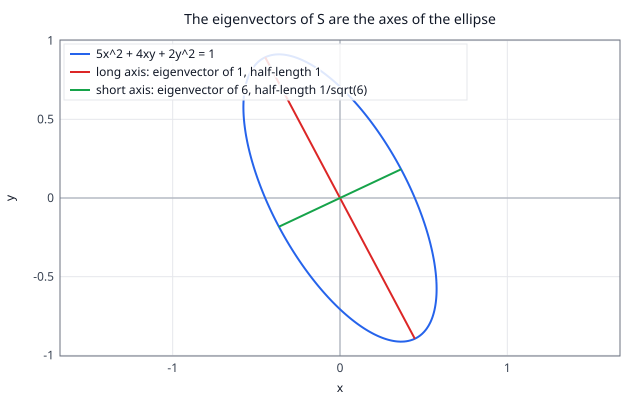

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
p = show(implicitplot(5*x^2 + 4*x*y + 2*y^2 == 1, x, -1.2, 1.2, y, -1.2, 1.2), parametric(-s/sqrt(5), 2*s/sqrt(5), s, -1, 1), parametric(2*s/sqrt(30), s/sqrt(30), s, -1, 1));
p = legend(p, "5x^2 + 4xy + 2y^2 = 1", "long axis: eigenvector of 1, half-length 1", "short axis: eigenvector of 6, half-length 1/sqrt(6)");
labels(title(p, "The eigenvectors of S are the axes of the ellipse"), "x", "y")

**Try this.** What shape is $x^2 + 4xy + y^2 = 1$? (Find the eigenvalues of its matrix $[1\ 2;\ 2\ 1]$; what does a
negative eigenvalue do to $u_1^2\lambda_1 + u_2^2\lambda_2 = 1$?)

## 3. Positive definite matrices

A symmetric matrix is **positive definite** if $x^TSx > 0$ for every $x \ne 0$: the quadratic form is a bowl with its
bottom at the origin. Five equivalent tests, each useful in a different situation:

1. all **eigenvalues** are positive;
2. all **pivots** (from elimination, without row exchanges) are positive;
3. all **leading determinants** (top-left $1\times1$, $2\times2$, ...) are positive;
4. the **energy** $x^TSx$ is positive for $x \ne 0$;
5. $S = A^TA$ for some $A$ with independent columns.

For $S = [5\ 2;\ 2\ 2]$: eigenvalues 1 and 6; pivots 5 and $6/5$ (from `lu`); leading determinants 5 and 6; energy
$5x^2 + 4xy + 2y^2 = 5(x + \tfrac25 y)^2 + \tfrac65 y^2 > 0$, a sum of squares with the pivots as coefficients.
`posdef` runs test 2:

In [6]:
[L, U, P] = lu(S)
det(S)
posdef(S)
posdef([1 2; 2 1])

L = [  1, 0;
 2/5, 1]
U = [5,   2;
 0, 6/5]
P = [1, 0;
 0, 1]
6

> `det`: Determinant.

true

> Positive definite: symmetric, and elimination gives the pivots 5, 6/5, all positive (so chol(A) exists, every eigenvalue is positive and xᵀAx > 0 for every x ≠ 0).

false

> Not positive definite: pivot 2 is -3, and every pivot of a positive definite matrix is positive.

$[1\ 2;\ 2\ 1]$ fails: its second pivot is $1 - 4 = -3$, its determinant $-3$, its eigenvalues $3$ and $-1$, and at
$x = [1\ {-1}]$ the energy is $1 - 4 + 1 = -2$. The saddle of the Try this above.

Test 5 explains where positive definite matrices come from: $x^TA^TAx = |Ax|^2 \ge 0$, and it is 0 only when $Ax = 0$.
The normal equations matrix $A^TA$ of least squares (lesson 5) is positive definite whenever $A$ has independent columns.

A classic example from physics and engineering, the matrix of a chain of springs (or of the second difference
$-u'' $ on a grid):

In [7]:
K = [2 -1 0; -1 2 -1; 0 -1 2];
eig(K)
posdef(K)

[2, sqrt(2)+2, 2-sqrt(2)]

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

true

> Positive definite: symmetric, and elimination gives the pivots 2, 3/2, 4/3, all positive (so chol(A) exists, every eigenvalue is positive and xᵀAx > 0 for every x ≠ 0).

**Try this.** For which numbers $b$ is $[1\ b;\ b\ 4]$ positive definite? Use the determinant test.

## 4. Cholesky: $S = LL^T$

For a positive definite matrix, elimination $S = LDL^T$ has positive pivots in $D$, so we can take square roots and
split them evenly: $S = (L\sqrt D)(L\sqrt D)^T = LL^T$ with a new lower triangular $L$. That is the **Cholesky
factorization**, `chol`. It is LU at half the cost (symmetry means only half the work), it is how software solves
symmetric positive definite systems, and it is the quickest test: Cholesky succeeds exactly when $S$ is positive
definite.

In [8]:
L = chol(S)
L*transpose(L)
chol(K)

[    sqrt(5),          0;
 2*sqrt(5)/5, sqrt(30)/5]

> A = L*Lᵀ with L lower triangular. It exists exactly when A is symmetric positive definite, which elimination shows: the pivots are 5, 6/5, all positive, and the diagonal of L holds their square roots. It is LU for symmetric matrices, at half the cost.

[5, 2;
 2, 2]

[   sqrt(2),          0,           0;
 -sqrt(2)/2,  sqrt(6)/2,           0;
          0, -sqrt(6)/3, 2*sqrt(3)/3]

> A = L*Lᵀ with L lower triangular. It exists exactly when A is symmetric positive definite, which elimination shows: the pivots are 2, 3/2, 4/3, all positive, and the diagonal of L holds their square roots. It is LU for symmetric matrices, at half the cost.

The diagonal of $L$ holds the square roots of the pivots: $\sqrt5$ and $\sqrt{6/5} = \sqrt{30}/5$ for $S$.

In statistics, $LL^T$ is how you simulate correlated random data: if $z$ has independent standard normal entries,
$Lz$ has covariance matrix $LL^T = S$.

**Try this.** Find the Cholesky factor of $[4\ 2;\ 2\ 5]$ by hand: $L = [a\ 0;\ b\ c]$ with $a^2 = 4$, $ab = 2$,
$b^2 + c^2 = 5$.

## 5. Minimum, maximum or saddle

In [multivariable lesson 3](../multivariable/03-optimization.ipynb) a critical point was classified by the **Hessian**,
the symmetric matrix of second derivatives. Near a critical point, $f(x) \approx f(x_0) + \tfrac12(x - x_0)^TH(x - x_0)$:
a quadratic form. So:

* $H$ positive definite: a **minimum** (a bowl);
* $-H$ positive definite (all eigenvalues negative): a **maximum**;
* eigenvalues of both signs: a **saddle**.

In [9]:
H = hessian(x^2 + x*y + y^2, [x y])
posdef(H)
eig(hessian(x^2 + 4*x*y + y^2, [x y]))

[2, 1;
 1, 2]

> The Hessian holds the second partial derivatives ∂²f/∂x_i∂x_j; it is symmetric when they are continuous. At a critical point it decides the shape: all eigenvalues positive means a minimum, all negative a maximum, mixed signs a saddle (classify does this).

true

> Positive definite: symmetric, and elimination gives the pivots 2, 3/2, all positive (so chol(A) exists, every eigenvalue is positive and xᵀAx > 0 for every x ≠ 0).

[-2, 6]

> `eig`: Eigenvalues of a square matrix (exact when the characteristic polynomial factors or has degree 2, numeric otherwise), and the characteristic polynomial det(A - x*I).

$x^2 + xy + y^2$ has a minimum at the origin; $x^2 + 4xy + y^2$ (eigenvalues $6$ and $-2$) a saddle.

**Try this.** Classify the critical point of $f = 3x^2 - 2xy + 3y^2$ at the origin with `posdef(hessian(...))`.

## Exercises

1. **Spectral theorem.** Write $[2\ 1;\ 1\ 2]$ as $Q\Lambda Q^T$, and as $\lambda_1q_1q_1^T + \lambda_2q_2q_2^T$.
2. **Ellipse.** Find the axes and half-lengths of the ellipse $2x^2 + 2xy + 2y^2 = 1$.
3. **Five tests.** Check all five tests for $K = [2\ {-1}\ 0;\ {-1}\ 2\ {-1};\ 0\ {-1}\ 2]$. For test 5, find an $A$
   with $A^TA = K$. (Hint: Cholesky.)
4. **Not definite.** Show that $[1\ 1;\ 1\ 1]$ is positive *semi*definite: $x^TSx \ge 0$, but $= 0$ for some
   $x \ne 0$. Which $x$?
5. **Covariance.** The covariance matrix of data is $X^TX/(n-1)$ for centered data $X$. Why is it always positive
   semidefinite?

## Hints and answers

* **Section 1, Try this.** $\lambda = 1$ with $[1\ 1]$ (kept), $\lambda = -1$ with $[1\ {-1}]$ (flipped).
* **Section 2, Try this.** Eigenvalues $3$ and $-1$: $3u_1^2 - u_2^2 = 1$ is a **hyperbola**.
* **Section 3, Try this.** $\det = 4 - b^2 > 0$ (and $1 > 0$): $-2 < b < 2$.
* **Section 4, Try this.** $a = 2$, $b = 1$, $c = 2$: $L = [2\ 0;\ 1\ 2]$. Check: `chol([4 2; 2 5])`.
* **Section 5, Try this.** $H = [6\ {-2};\ {-2}\ 6]$, pivots 6 and $16/3$: positive definite, a minimum.
* **Exercise 1.** $\lambda = 1, 3$ with $q = [-1\ 1]/\sqrt2$, $[1\ 1]/\sqrt2$:
  $S = 1\cdot\tfrac12[1\ {-1};\ {-1}\ 1] + 3\cdot\tfrac12[1\ 1;\ 1\ 1]$.
* **Exercise 2.** $S = [2\ 1;\ 1\ 2]$, eigenvalues 1 and 3: half-length 1 along $[1\ {-1}]$, $1/\sqrt3$ along $[1\ 1]$.
* **Exercise 3.** Eigenvalues $2, 2 \pm \sqrt2$, pivots $2, 3/2, 4/3$, leading determinants $2, 3, 4$; energy
  $x_1^2 + (x_1 - x_2)^2 + (x_2 - x_3)^2 + x_3^2$; $A = L^T$ with `L = chol(K)`.
* **Exercise 4.** $x^TSx = (x_1 + x_2)^2$, zero for $x = [1\ {-1}]$. Eigenvalues 2 and 0.
* **Exercise 5.** $x^T X^TX x = |Xx|^2 \ge 0$, as in test 5.

## Sources

1. G. Strang, *Introduction to Linear Algebra*, 6th ed., Wellesley-Cambridge Press (2023), chapter 7.
2. G. Strang, *Linear Algebra and Learning from Data*, Wellesley-Cambridge Press (2019), sections I.7 and I.8.
3. A.-L. Cholesky (published by Commandant Benoît), "Note sur une méthode de résolution des équations normales",
   *Bulletin géodésique* 2 (1924) 67–77.
4. N. J. Higham, *Accuracy and Stability of Numerical Algorithms*, 2nd ed., SIAM (2002), chapter 10.